# Forecast demo
Load a trained checkpoint, predict one-hour-ahead masks on a validation stretch, and plot them with `plot_height_lon_sequence`.

Run this notebook from the project folder (next to `config.py`, `data.py`, `model.py`, `plots.py`).

In [ ]:
import tempfile
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
from heimdall.cloud_forecasting.config import N_CH, VAL_FRAC
from heimdall.cloud_forecasting.data import load_channels
from heimdall.cloud_forecasting.model import ConvLSTM3d

# ---- edit these ----
DATA_PATH = "../data/era5/boston_subset/c3dir_like_era5_20260601_20260615_N45.5_W74_S39.5_E68.nc"
CKPT_PATH = "../training_runs/15day_epoch50/convlstm3d_best.pt"
K = 4          # forecasted hours per plot

## Load data and model
Settings (`t_in`, `hidden`, `alt_max`) come from the checkpoint, and the validation split is rebuilt the same way as in training.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

ckpt = torch.load(CKPT_PATH, map_location=device)
T_IN = ckpt["t_in"]

model = ConvLSTM3d(N_CH, ckpt["hidden"]).to(device)
model.load_state_dict(ckpt["model"])
model.eval()

x = load_channels(DATA_PATH, ckpt["alt_max"])
split = int(x.sizes["time"] * (1 - VAL_FRAC))        # same chronological split as training
val = x.isel(time=slice(split, None))
w = torch.from_numpy(val.values)                      # (hours, channel, alt, lat, lon)

n_starts = len(w) - T_IN - K + 1
print(f"device {device} | validation hours {len(w)} | valid start hours 0..{n_starts - 1}")

device mps | validation hours 72 | valid start hours 0..62


## Predict and plot one stretch
`start` is the first input hour within the validation period. The stretch is `T_IN` input hours followed by `K` forecasted hours.

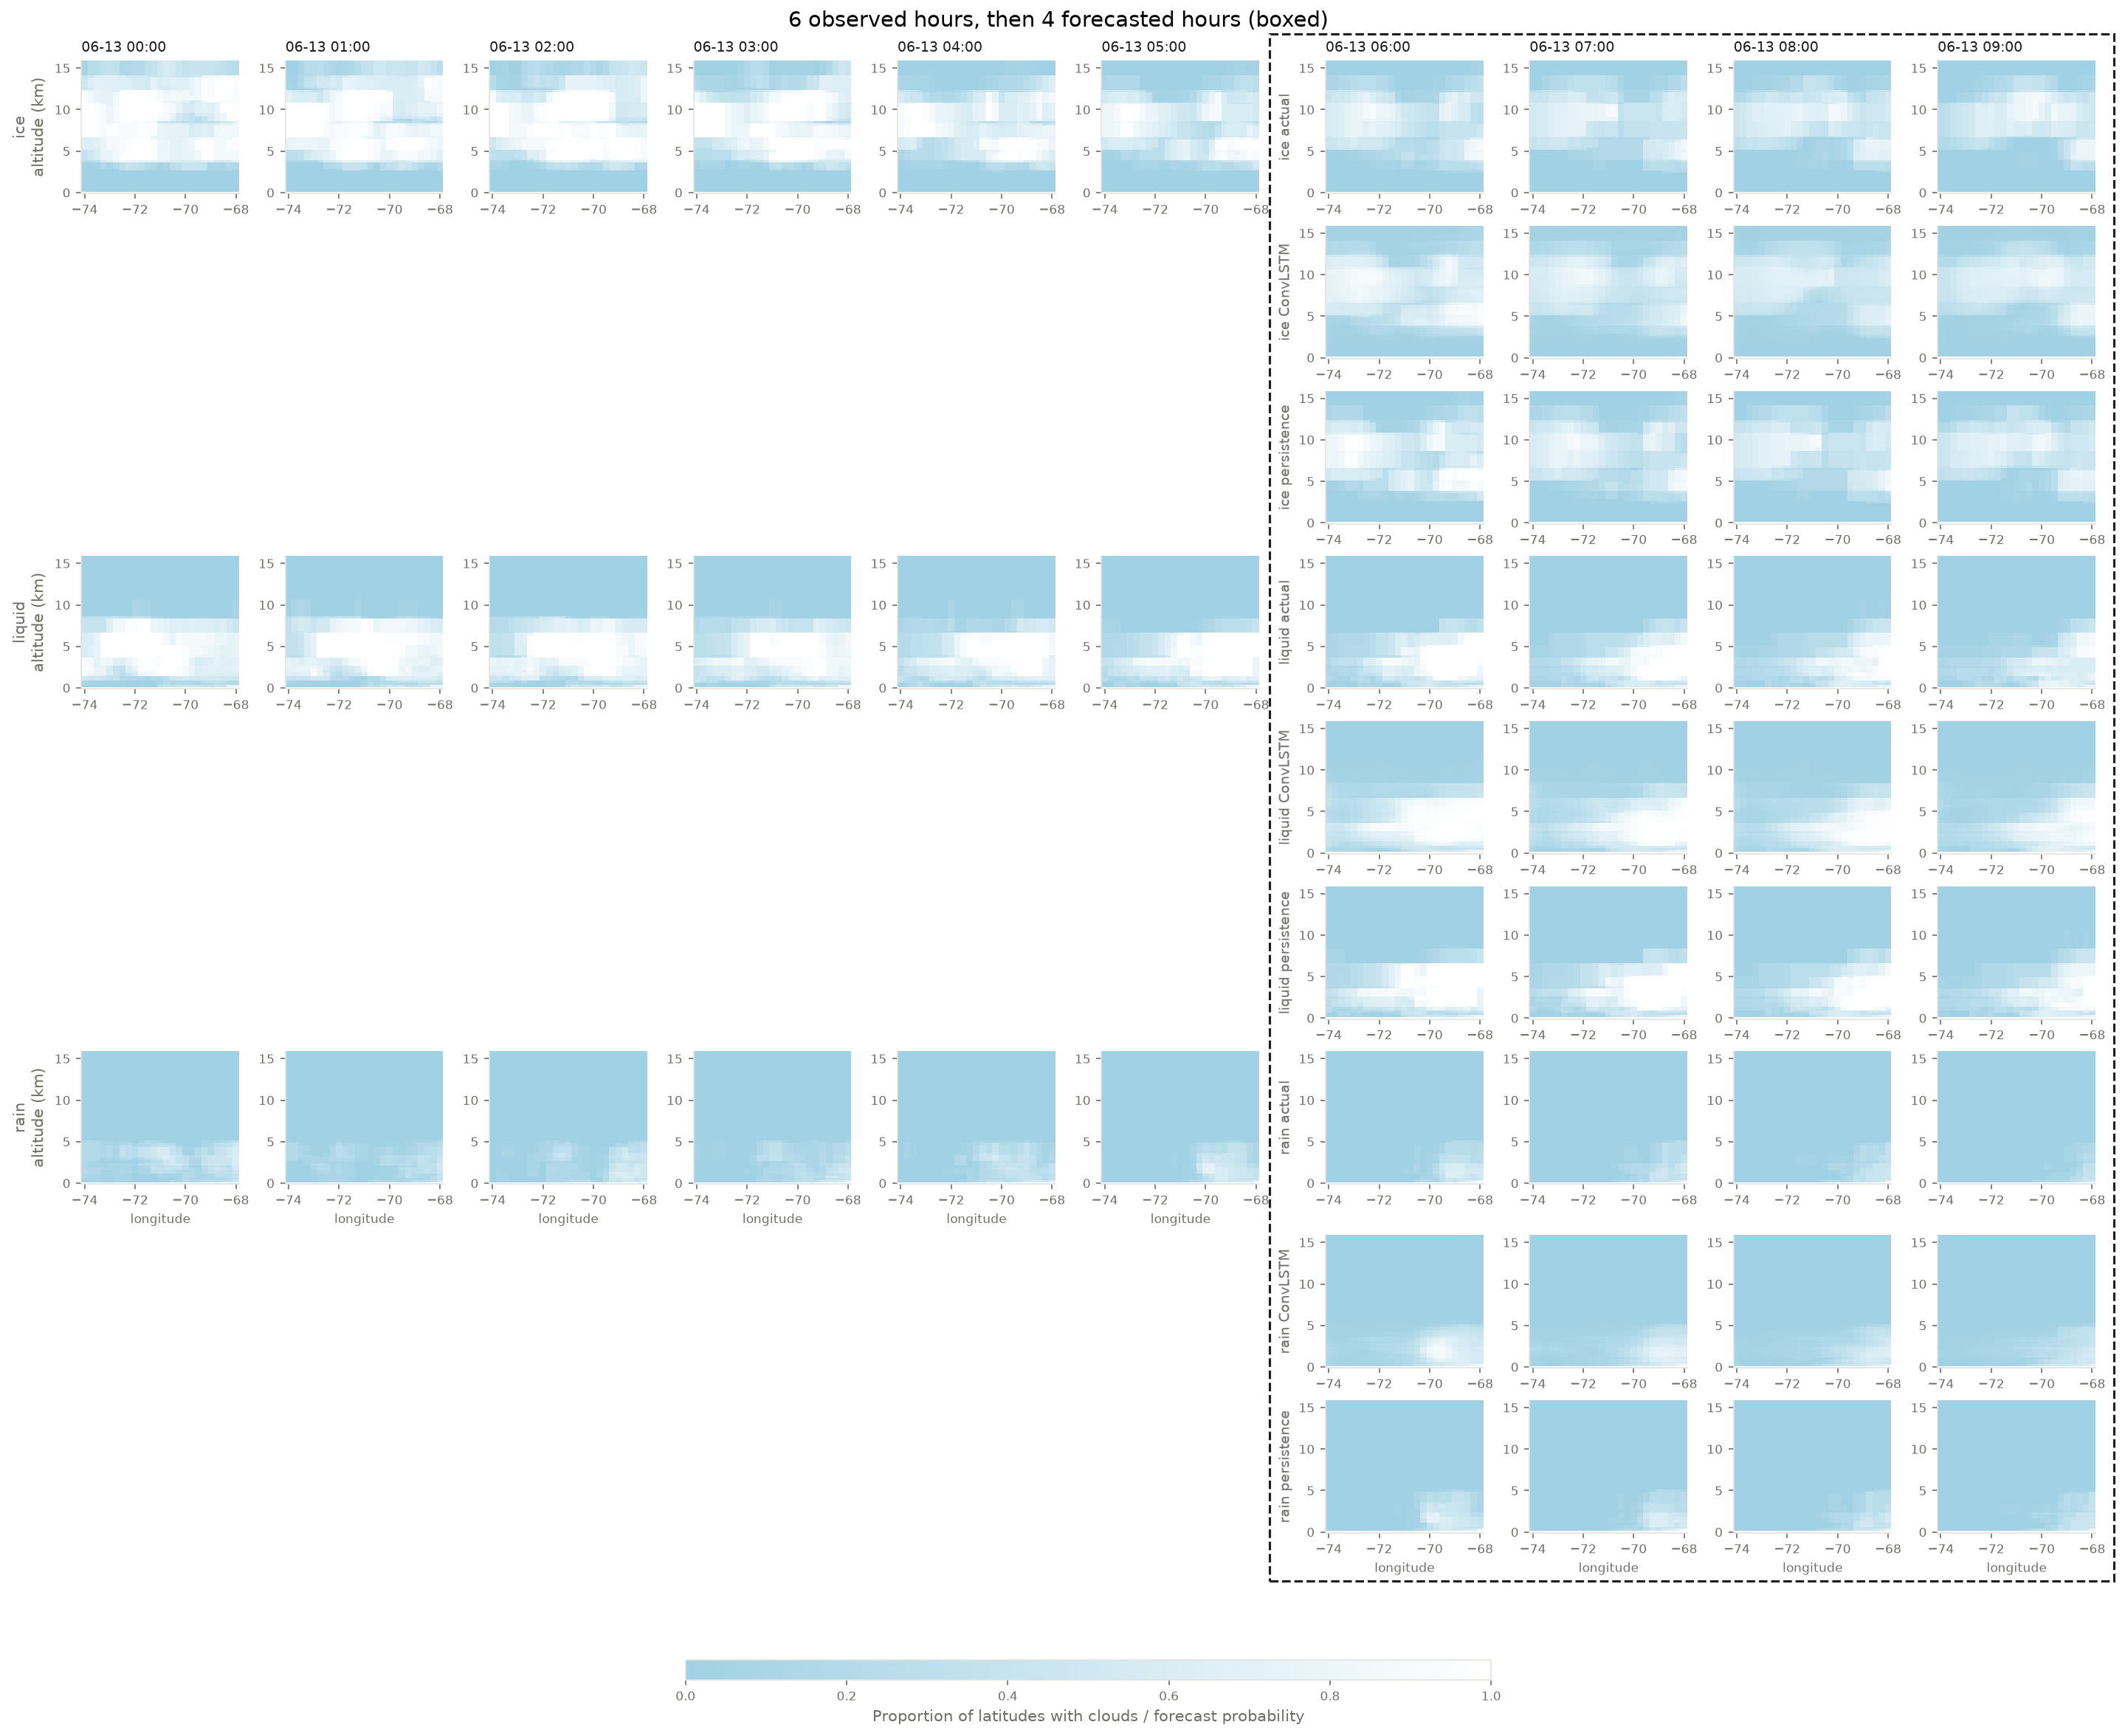

In [ ]:
import importlib
from heimdall.cloud_forecasting import plots

importlib.reload(plots)
from heimdall.cloud_forecasting.plots import plot_height_lon_compare

def forecast_stretch(start, k=K):
    """k one-hour-ahead forecasts in a row: window j forecasts hour T_IN + j of the stretch."""
    seq = w[start:start + T_IN + k]
    x_in = torch.stack([seq[j:j + T_IN, :N_CH] for j in range(k)])
    with torch.no_grad():
        prob = torch.sigmoid(model(x_in.to(device))).cpu().numpy()
    times = pd.to_datetime(val.time.values[start:start + T_IN + k])
    return seq, prob, times

def show(start, k=K, path=None):
    seq, prob, times = forecast_stretch(start, k)
    path = path or Path(tempfile.gettempdir()) / f"forecast_{start}.png"
    plot_height_lon_compare(seq[:, 3:N_CH].numpy(), prob, seq[:, N_CH].numpy(),
                             x.alt.values, x.longitude.values, times, path)
    display(Image(filename=str(path)))

show(start=0)

## Browse other stretches
Run the loop below to save every non-overlapping stretch to a folder.

In [ ]:
out_dir = Path("runs/forecast_height_lon")
out_dir.mkdir(parents=True, exist_ok=True)

for start in range(0, n_starts, K):
    seq, prob, times = forecast_stretch(start)
    plot_height_lon_compare(seq[:, 3:N_CH].numpy(), prob, seq[:, N_CH].numpy(), x.alt.values, x.longitude.values,
                             times, out_dir / f"{times[T_IN]:%Y-%m-%d_%H}h.png", level=LEVEL)
print(f"saved {len(range(0, n_starts, K))} plots to {out_dir}/")